In [ ]:
!pip install -q open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00


## CONFIG

In [ ]:
import os

RUN_STAGES   = [1, 2]     # which stages to run
RUN_CASCADE  = True       # end-to-end Stage1 -> Stage2 evaluation (needs both stages)
AUG          = "us"       # "us" (ultrasound-physics) | "standard" (ablation) | "none" (ablation)
POOL         = "cls"      # "cls" | "fan_attn" (fan-masked attention pooling)

RUN_ZERO_SHOT    = True
RUN_LINEAR_PROBE = True
RUN_FINETUNE     = True
REUSE_CKPT       = True   # reuse best.pt found in /kaggle/input (resume after a crash)

EPOCHS, BATCH, ACCUM    = 25, 32, 1
LR_HEAD, LR_BACKBONE    = 1e-3, 2e-5        # LR_BACKBONE = LR of the top ViT block
LAYER_DECAY, WD         = 0.8, 0.05
WARMUP_EPOCHS, PATIENCE = 1, 6
DROPOUT, MC_T           = 0.3, 30
GRAD_CKPT               = True
NUM_WORKERS             = 4
SEED                    = 42
DEBUG                   = False           # True = tiny subset + 1 epoch (quick test of the whole notebook)

# McNemar baselines: leave empty -> auto-detected from any attached CSV whose name contains "stage1"/"stage2"
# and that has columns image,y_pred (y_true optional; labels may be class names or indices).
BASELINE_PRED_CSV = {1: "", 2: ""}

WORK = "/kaggle/working"

## 1. Locate dataset + metadata

In [ ]:
import glob

def find_dataset_root():
    for depth in range(1, 6):
        for c in sorted(glob.glob("/kaggle/input" + "/*" * depth)):
            if os.path.isdir(c) and os.path.basename(c) != "brain_subplanes" and \
               all(os.path.isdir(f"{c}/{s}") for s in ("train", "val", "test")):
                return c
    return None

ROOT = find_dataset_root()
assert ROOT is not None, "train/val/test not found under /kaggle/input — click 'Add Input' and attach fetal-planes-final"
print("ROOT:", ROOT, "|", sorted(os.listdir(ROOT)))

META_CSV = None
for c in sorted(glob.glob(f"{ROOT}/**/FETAL_PLANES_DB_data*", recursive=True) +
                glob.glob("/kaggle/input/**/FETAL_PLANES_DB_data*", recursive=True)):
    if os.path.isfile(c) and c.lower().endswith((".xlsx", ".xls", ".csv")):
        META_CSV = c; break
print("META:", META_CSV)

if 2 in RUN_STAGES and not os.path.isdir(f"{ROOT}/brain_subplanes/train"):
    print("brain_subplanes/{train,val,test} not found -> Stage 2 and cascade skipped")
    RUN_STAGES = [s for s in RUN_STAGES if s != 2]; RUN_CASCADE = False

ROOT: /kaggle/input/datasets/paravibhatia/fetal-planes-final | ['FETAL_PLANES_DB_data.xlsx', 'brain_subplanes', 'test', 'train', 'val', 'val_patients.csv']
META: /kaggle/input/datasets/paravibhatia/fetal-planes-final/FETAL_PLANES_DB_data.xlsx


## 2. Imports, device

In [ ]:
import re, json, math, time, random, shutil
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T, torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from IPython.display import display

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = torch.float16 if DEVICE == "cuda" else torch.bfloat16
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: no GPU — turn on Accelerator = GPU T4")

def autocast():
    return torch.autocast(device_type=DEVICE, dtype=AMP_DTYPE)

IMG, PATCH = 224, 14
GRID = IMG // PATCH
def pid_of(name):
    m = re.match(r"(Patient\d+)", name)
    return m.group(1) if m else name

META = None
if META_CSV:
    META = (pd.read_excel(META_CSV) if META_CSV.lower().endswith((".xlsx", ".xls"))
            else pd.read_csv(META_CSV, sep=None, engine="python"))
    META.columns = [c.strip() for c in META.columns]
    META["Image_name"] = META["Image_name"].astype(str).str.replace(r"\.png$", "", regex=True)
    META = META.drop_duplicates("Image_name").set_index("Image_name")
    print(META.head(3))

Tesla T4 15.6 GB
                             Patient_num  Plane  Brain_plane Operator  \
Image_name                                                              
Patient00001_Plane1_1_of_15            1  Other  Not A Brain    Other   
Patient00001_Plane1_2_of_15            1  Other  Not A Brain    Other   
Patient00001_Plane1_3_of_15            1  Other  Not A Brain    Other   

                            US_Machine  Train  
Image_name                                     
Patient00001_Plane1_1_of_15      Aloka      1  
Patient00001_Plane1_2_of_15      Aloka      1  
Patient00001_Plane1_3_of_15      Aloka      1  


## 3. Data loading (letterbox 224 + scan-region mask, cached in RAM)

In [ ]:
def letterbox_gray(path, s=IMG):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    h, w = g.shape
    r = s / max(h, w)
    nh, nw = max(1, round(h * r)), max(1, round(w * r))
    g = cv2.resize(g, (nw, nh), interpolation=cv2.INTER_AREA)
    out = np.zeros((s, s), np.uint8)
    y0, x0 = (s - nh) // 2, (s - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = g
    return out

def scan_mask(g):
    m = (cv2.GaussianBlur(g, (5, 5), 0) > 4).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    if n > 1:
        m = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    if filled.mean() < 0.10:
        filled[:] = 1
    return filled

def load_split(split_dir, split, classes=None, limit=None):
    d = f"{split_dir}/{split}"
    if classes is None:
        classes = sorted(c for c in os.listdir(d) if os.path.isdir(f"{d}/{c}"))
    paths, labels = [], []
    for ci, c in enumerate(classes):
        fs = sorted(f for f in os.listdir(f"{d}/{c}") if f.lower().endswith((".png", ".jpg", ".jpeg")))
        paths += [f"{d}/{c}/{f}" for f in fs]; labels += [ci] * len(fs)
    labels = np.array(labels)
    if limit:
        idx = np.random.RandomState(0).permutation(len(paths))[:limit]
        paths, labels = [paths[i] for i in idx], labels[idx]
    with ThreadPoolExecutor(16) as ex:
        imgs = np.stack(list(ex.map(letterbox_gray, paths)))
    masks = np.stack([scan_mask(g) for g in imgs])
    names = [os.path.splitext(os.path.basename(p))[0] for p in paths]
    return dict(imgs=imgs, masks=masks, y=labels, names=names,
                pids=np.array([pid_of(n) for n in names]), classes=classes)

def subset(d, idx):
    idx = np.asarray(idx)
    return dict(imgs=d["imgs"][idx], masks=d["masks"][idx], y=d["y"][idx],
                names=[d["names"][i] for i in idx], pids=d["pids"][idx], classes=d["classes"])

## 4. Augmentation + dataset

In [ ]:
class USAug:
    """Ultrasound-physics augmentation: fan-masked affine, gamma speckle, TGC, gamma, resolution degradation."""
    def __call__(self, g, m):
        r = np.random
        if r.rand() < 0.8:
            M = cv2.getRotationMatrix2D((IMG / 2, IMG / 2), r.uniform(-10, 10), r.uniform(0.9, 1.1))
            M[:, 2] += r.uniform(-0.06, 0.06, 2) * IMG
            g = cv2.warpAffine(g, M, (IMG, IMG), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            m = cv2.warpAffine(m, M, (IMG, IMG), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        if r.rand() < 0.5:
            L = r.uniform(10, 25)
            g = g * r.gamma(L, 1.0 / L, g.shape).astype(np.float32)
        if r.rand() < 0.5:
            d = np.linspace(0, 1, IMG, dtype=np.float32)[:, None] - 0.5
            g = g * (1 + r.uniform(-0.3, 0.3) * d + r.uniform(-0.2, 0.2) * d ** 2)
        if r.rand() < 0.5:
            g = np.clip(g, 0, 1) ** r.uniform(0.8, 1.25)
        if r.rand() < 0.3:
            k = max(8, int(IMG * r.uniform(0.5, 0.85)))
            g = cv2.resize(cv2.resize(g, (k, k), interpolation=cv2.INTER_AREA), (IMG, IMG), interpolation=cv2.INTER_LINEAR)
        return np.clip(g, 0, 1).astype(np.float32), m

class StdAug:
    def __call__(self, g, m):
        r = np.random
        g = (g - g.mean()) * r.uniform(0.8, 1.2) + g.mean() + r.uniform(-0.2, 0.2)
        return np.clip(g, 0, 1).astype(np.float32), m

AUGS = {"us": USAug(), "standard": StdAug(), "none": None}

class PlaneDS(Dataset):
    def __init__(self, d, aug=None):
        self.d, self.aug = d, aug
    def __len__(self):
        return len(self.d["y"])
    def __getitem__(self, i):
        g = self.d["imgs"][i].astype(np.float32) / 255.0
        m = self.d["masks"][i]
        if self.aug is not None:
            g, m = self.aug(g, m)
        g = g * m
        x = torch.from_numpy(np.ascontiguousarray(g))[None].repeat(3, 1, 1)
        pm = cv2.resize(m.astype(np.float32), (GRID, GRID), interpolation=cv2.INTER_AREA) > 0.3
        return x, torch.from_numpy(pm), int(self.d["y"][i]), i

def make_loader(d, train=False, bs=BATCH):
    ds = PlaneDS(d, AUGS[AUG] if train else None)
    kw = dict(batch_size=bs, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=train and NUM_WORKERS > 0)
    if train:
        y = d["y"]; w = 1.0 / np.maximum(np.bincount(y, minlength=len(d["classes"])), 1)
        sampler = WeightedRandomSampler(torch.as_tensor(w[y], dtype=torch.double), len(y), replacement=True)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=False, **kw)

## 5. FetalCLIP model

In [ ]:
import open_clip, urllib.request
from huggingface_hub import hf_hub_download, list_repo_files

CFG_PATH = f"{WORK}/FetalCLIP_config.json"
if not os.path.exists(CFG_PATH):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/BioMedIA-MBZUAI/FetalCLIP/main/FetalCLIP_config.json", CFG_PATH)
HF_REPO = "numansaeed/fetalclip-model"
_files = list_repo_files(HF_REPO)
W_PATH = hf_hub_download(HF_REPO, "FetalCLIP_weights.pt" if "FetalCLIP_weights.pt" in _files
                         else [f for f in _files if f.endswith((".pt", ".bin", ".safetensors"))][0])
print(json.load(open(CFG_PATH)), "\nweights:", W_PATH)

def load_fetalclip():
    open_clip.factory._MODEL_CONFIGS["FetalCLIP"] = json.load(open(CFG_PATH))
    model, _, pre = open_clip.create_model_and_transforms("FetalCLIP", pretrained=W_PATH)
    tok = open_clip.get_tokenizer("FetalCLIP")
    norm = [t for t in pre.transforms if isinstance(t, T.Normalize)][0]
    return model, tok, tuple(float(v) for v in norm.mean), tuple(float(v) for v in norm.std)

class FetalCLIPClassifier(nn.Module):
    """FetalCLIP image encoder -> pooling -> Dropout -> FC. Input: [0,1] images (normalised inside)."""
    def __init__(self, visual, n_cls, mean, std, pool="cls", p_drop=DROPOUT):
        super().__init__()
        self.visual, self.pool = visual, pool
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))
        if pool == "fan_attn":
            self.visual.output_tokens = True
            width = visual.transformer.width
            self.tok_norm = nn.LayerNorm(width)
            self.attn = nn.Sequential(nn.Linear(width, 256), nn.Tanh(), nn.Linear(256, 1))
            dim = width
        else:
            self.visual.output_tokens = False
            dim = visual.output_dim
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(dim, n_cls) if n_cls else nn.Identity()

    def embed(self, x, pmask=None, return_attn=False):
        x = (x - self.mean) / self.std
        out = self.visual(x)
        if self.pool == "cls":
            return out[0] if isinstance(out, tuple) else out
        _, tok = out
        tok = self.tok_norm(tok)
        a = self.attn(tok).squeeze(-1).float()
        pm = pmask.flatten(1)
        pm = pm | ~pm.any(1, keepdim=True)
        a = torch.softmax(a.masked_fill(~pm, float("-inf")), -1)      # exactly 0 outside the fan
        z = (a.unsqueeze(-1).to(tok.dtype) * tok).sum(1)
        return (z, a) if return_attn else z

    def head(self, z):
        return self.fc(self.drop(z))

    def forward(self, x, pmask=None):
        return self.head(self.embed(x, pmask))

def build_classifier(n_cls, ckpt=None):
    clip_model, _, mean, std = load_fetalclip()
    model = FetalCLIPClassifier(clip_model.visual, n_cls, mean, std, pool=POOL)
    del clip_model
    if ckpt:
        sd = torch.load(ckpt, map_location="cpu")
        model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in sd.items()})
    return model.to(DEVICE)

FetalCLIP_weights.pt:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

{'embed_dim': 768, 'vision_cfg': {'image_size': 224, 'layers': 24, 'width': 1024, 'patch_size': 14}, 'text_cfg': {'context_length': 117, 'vocab_size': 49408, 'width': 768, 'heads': 12, 'layers': 12}} 
weights: /root/.cache/huggingface/hub/models--numansaeed--fetalclip-model/snapshots/2c02ad7b3eea314a328c5ebe5b81be4ef3a4d5db/FetalCLIP_weights.pt


## 6. Metrics, calibration, statistics

In [ ]:
def ece_from(conf, correct, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def ece_score(probs, y):
    return ece_from(probs.max(1), (probs.argmax(1) == y).astype(float))

def metrics(y, probs):
    pred = probs.argmax(1)
    return dict(acc=100 * accuracy_score(y, pred),
                macro_f1=100 * f1_score(y, pred, average="macro"),
                bal_acc=100 * balanced_accuracy_score(y, pred),
                ece=ece_score(probs, y),
                nll=float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1)).mean()))

def entropy(p):
    return -(p * np.log(np.clip(p, 1e-12, 1))).sum(-1)

def risk_coverage(correct, score):
    order = np.argsort(-score)
    c = np.asarray(correct, float)[order]
    n = len(c); cov = np.arange(1, n + 1) / n
    sel_acc = np.cumsum(c) / np.arange(1, n + 1)
    return cov, sel_acc, float(np.mean(1 - sel_acc))

def acc_at_coverage(cov, sel_acc, c):
    return float(100 * sel_acc[min(len(cov) - 1, int(np.ceil(c * len(cov))) - 1)])

def cluster_bootstrap_ci(y, pred, conf, pids, B=2000, seed=0):
    """Patient-level bootstrap 95% CIs (all images of a patient resampled together)."""
    rng = np.random.RandomState(seed)
    groups = list(pd.Series(np.arange(len(y))).groupby(np.asarray(pids)).apply(np.array).values)
    stats = []
    for _ in range(B):
        idx = np.concatenate([groups[k] for k in rng.randint(0, len(groups), len(groups))])
        yy, pp, cc = y[idx], pred[idx], conf[idx]
        stats.append([100 * accuracy_score(yy, pp), 100 * f1_score(yy, pp, average="macro"),
                      100 * balanced_accuracy_score(yy, pp), ece_from(cc, (pp == yy).astype(float))])
    lo, hi = np.percentile(np.array(stats), [2.5, 97.5], axis=0)
    return {k: (round(float(l), 4), round(float(h), 4)) for k, l, h in zip(["acc", "macro_f1", "bal_acc", "ece"], lo, hi)}

def mcnemar_test(correct_a, correct_b):
    from statsmodels.stats.contingency_tables import mcnemar
    a, b_ = np.asarray(correct_a, bool), np.asarray(correct_b, bool)
    b = int(np.sum(a & ~b_)); c = int(np.sum(~a & b_))
    tbl = [[int(np.sum(a & b_)), b], [c, int(np.sum(~a & ~b_))]]
    r = mcnemar(tbl, exact=(b + c) < 25, correction=True)
    return dict(fetalclip_right_base_wrong=b, fetalclip_wrong_base_right=c,
                statistic=float(r.statistic), p_value=float(r.pvalue))

def fit_temperature(logits, y):
    lt = torch.tensor(logits, dtype=torch.float32); yt = torch.tensor(y)
    log_t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(lt / log_t.exp(), yt); loss.backward(); return loss
    opt.step(closure)
    return float(log_t.exp())

def per_machine(names, correct):
    if META is None or "US_Machine" not in META.columns:
        return None
    mach = pd.Series(names).map(META["US_Machine"]).fillna("unknown").values
    df = pd.DataFrame(dict(machine=mach, correct=np.asarray(correct, float)))
    return df.groupby("machine")["correct"].agg(n="size", acc=lambda s: 100 * s.mean()).round(2)

def plot_cm(y, pred, classes, title, path):
    n = len(classes)
    cm = confusion_matrix(y, pred, labels=range(n)); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    fig, ax = plt.subplots(figsize=(1.3 * n + 2, 1.1 * n + 2))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(n)); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(classes)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def save_json(obj, path):
    json.dump(obj, open(path, "w"), indent=2, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

## 7. Feature extraction (+ 6-view TTA) and MC Dropout head

In [ ]:
VIEWS = ["id", "hflip", "rot+5", "rot-5", "zoom+", "zoom-"]
_AFF = {"rot+5": (5, 1.0), "rot-5": (-5, 1.0), "zoom+": (0, 1.06), "zoom-": (0, 0.94)}

def apply_view(x, pm, v):
    if v == "id":
        return x, pm
    if v == "hflip":
        return x.flip(-1), pm.flip(-1)
    ang, sc = _AFF[v]
    x2 = TF.affine(x, angle=ang, translate=[0, 0], scale=sc, shear=[0.0], fill=0.0)
    pm2 = TF.affine(pm[:, None].float(), angle=ang, translate=[0, 0], scale=sc, shear=[0.0],
                    interpolation=T.InterpolationMode.NEAREST, fill=0.0)[:, 0] > 0.5
    return x2, pm2

@torch.no_grad()
def extract(model, d, views=("id",), bs=64):
    """(V, N, D) pooled embeddings (before dropout/FC)."""
    model.eval()
    Z = [[] for _ in views]
    for x, pm, _, _ in make_loader(d, train=False, bs=bs):
        x, pm = x.to(DEVICE, non_blocking=True), pm.to(DEVICE, non_blocking=True)
        for k, v in enumerate(views):
            xv, pv = apply_view(x, pm, v)
            with autocast():
                Z[k].append(model.embed(xv, pv).float().cpu())
    return torch.stack([torch.cat(z) for z in Z])

@torch.no_grad()
def head_probs(model, Z, temp=1.0, mc_T=0):
    """Average softmax over views (TTA) and MC-Dropout passes. Returns probs, entropy, mutual info, view-0 logits."""
    model.eval()
    dev = next(model.fc.parameters()).device
    det_logits = model.fc(Z[0].to(dev)).cpu().numpy()
    samples = []
    if mc_T > 0:
        model.drop.train()
        for _ in range(mc_T):
            for v in range(Z.shape[0]):
                samples.append(torch.softmax(model.head(Z[v].to(dev)) / temp, -1).cpu().numpy())
        model.drop.eval()
    else:
        for v in range(Z.shape[0]):
            samples.append(torch.softmax(model.fc(Z[v].to(dev)) / temp, -1).cpu().numpy())
    S = np.stack(samples)
    Pm = S.mean(0); H = entropy(Pm)
    return Pm, H, H - entropy(S).mean(0), det_logits

## 8. Zero-shot prompts

In [ ]:
PROMPT_BANK = {
    "abdomen": ["Ultrasound image of the fetal abdomen at the level of the stomach and umbilical vein.",
                "Fetal abdominal circumference plane.", "Transverse ultrasound view of the fetal abdomen."],
    "thalam":  ["Ultrasound image of the fetal brain in the trans-thalamic plane.",
                "Fetal head at the level of the thalami and cavum septi pellucidi."],
    "cerebel": ["Ultrasound image of the fetal brain in the trans-cerebellar plane.",
                "Fetal head at the level of the cerebellum and cisterna magna."],
    "ventric": ["Ultrasound image of the fetal brain in the trans-ventricular plane.",
                "Fetal head at the level of the lateral ventricles."],
    "brain":   ["Ultrasound image of the fetal brain.", "Fetal head transverse plane showing the brain.",
                "Fetal biparietal diameter plane of the head."],
    "femur":   ["Ultrasound image of the fetal femur.", "Fetal femur length measurement plane.",
                "Ultrasound of the fetal thigh bone."],
    "thorax":  ["Ultrasound image of the fetal thorax showing the four-chamber view of the heart.",
                "Fetal heart four chamber view.", "Transverse view of the fetal chest."],
    "cervix":  ["Ultrasound image of the maternal cervix.", "Transvaginal ultrasound of the uterine cervix.",
                "Cervical length measurement ultrasound."],
}
def prompts_for(cname):
    c = cname.lower()
    for k, v in PROMPT_BANK.items():
        if k in c:
            return v
    return None

## 9. Stage runner: zero-shot → linear probe → fine-tune → evaluation

In [ ]:
STAGE_INFO = {}    # per stage: classes, test data, outputs dir
SUMMARY = []       # rows for summary.csv

def zero_shot_and_probe(D, CLASSES, OUT, R):
    clip_model, tokenizer, MEAN, STD = load_fetalclip()
    clip_model = clip_model.to(DEVICE).eval()
    frozen = FetalCLIPClassifier(clip_model.visual, 0, MEAN, STD, pool="cls").to(DEVICE).eval()
    FZ = {s: extract(frozen, D[s])[0].numpy() for s in ("train", "val", "test")}
    yt = D["test"]["y"]

    if RUN_ZERO_SHOT:
        zs = [i for i, c in enumerate(CLASSES) if prompts_for(c)]
        if len(zs) >= 2:
            with torch.no_grad(), autocast():
                tf = []
                for i in zs:
                    t = F.normalize(clip_model.encode_text(tokenizer(prompts_for(CLASSES[i])).to(DEVICE)).float(), dim=-1)
                    tf.append(F.normalize(t.mean(0), dim=-1))
                tf = torch.stack(tf).cpu().numpy()
            keep = np.isin(yt, zs)
            zi = FZ["test"][keep]; zi = zi / np.linalg.norm(zi, axis=1, keepdims=True)
            probs = torch.softmax(torch.tensor(float(clip_model.logit_scale.exp()) * zi @ tf.T), -1).numpy()
            y_zs = np.searchsorted(zs, yt[keep])
            m = metrics(y_zs, probs)
            print("ZERO-SHOT:", {k: round(v, 4) for k, v in m.items()})
            print(classification_report(y_zs, probs.argmax(1), target_names=[CLASSES[i] for i in zs], digits=4, zero_division=0))
            R["zero_shot"] = dict(classes=[CLASSES[i] for i in zs], n=int(keep.sum()), **m)
            SUMMARY.append(dict(stage=R["stage"], method="zero-shot", n_classes=len(zs), **{k: round(v, 4) for k, v in m.items()}))

    if RUN_LINEAR_PROBE:
        sc = StandardScaler().fit(FZ["train"])
        Xtr, Xva, Xte = (sc.transform(FZ[s]) for s in ("train", "val", "test"))
        best = None
        for C in [0.001, 0.01, 0.1, 1.0, 10.0]:
            clf = LogisticRegression(C=C, max_iter=5000, class_weight="balanced").fit(Xtr, D["train"]["y"])
            f1v = f1_score(D["val"]["y"], clf.predict(Xva), average="macro")
            print(f"  probe C={C:<6} val macro-F1={100*f1v:.2f}")
            if best is None or f1v > best[0]:
                best = (f1v, C, clf)
        _, C, clf = best
        p = clf.predict_proba(Xte)
        m = metrics(yt, p)
        print(f"LINEAR PROBE (C={C}):", {k: round(v, 4) for k, v in m.items()})
        print(classification_report(yt, p.argmax(1), target_names=CLASSES, digits=4, zero_division=0))
        ci = cluster_bootstrap_ci(yt, p.argmax(1), p.max(1), D["test"]["pids"])
        pmach = per_machine(D["test"]["names"], p.argmax(1) == yt)
        if pmach is not None: display(pmach)
        R["linear_probe"] = dict(C=C, **m, ci95=ci, per_machine=None if pmach is None else pmach.to_dict())
        SUMMARY.append(dict(stage=R["stage"], method="linear probe", n_classes=len(CLASSES),
                            **{k: round(v, 4) for k, v in m.items()}, acc_ci95=ci["acc"], f1_ci95=ci["macro_f1"]))
        pd.DataFrame(dict(image=D["test"]["names"], y_true=yt, y_pred=p.argmax(1))).to_csv(
            f"{OUT}/linear_probe_test_preds.csv", index=False)

    del clip_model, frozen
    if DEVICE == "cuda": torch.cuda.empty_cache()

def param_groups(model):
    nL = len(model.visual.transformer.resblocks)
    def layer_id(n):
        if n.startswith(("class_embedding", "positional_embedding", "conv1", "ln_pre")):
            return 0
        if n.startswith("transformer.resblocks."):
            return int(n.split(".")[2]) + 1
        return nL + 1
    groups = {}
    for n, p in model.visual.named_parameters():
        if not p.requires_grad:
            continue
        lid = layer_id(n); no_wd = p.ndim < 2 or "embedding" in n
        g = groups.setdefault((lid, no_wd), {"params": [], "lr": LR_BACKBONE * LAYER_DECAY ** (nL + 1 - lid),
                                             "weight_decay": 0.0 if no_wd else WD})
        g["params"].append(p)
    head = [p for n, p in model.named_parameters() if not n.startswith("visual.")]
    return list(groups.values()) + [{"params": head, "lr": LR_HEAD, "weight_decay": 1e-4}]

def finetune(D, NC, OUT, RUN_NAME, R):
    found = sorted(glob.glob(f"/kaggle/input/**/{RUN_NAME}/best.pt", recursive=True)) if REUSE_CKPT else []
    if found:
        print("reusing checkpoint:", found[0])
        shutil.copy(found[0], f"{OUT}/best.pt")
        for f in ("history.csv", "curves.png"):
            src = os.path.join(os.path.dirname(found[0]), f)
            if os.path.exists(src): shutil.copy(src, f"{OUT}/{f}")
        R["finetune_reused_ckpt"] = found[0]
        return build_classifier(NC, f"{OUT}/best.pt").eval()

    seed_all(SEED)
    model = build_classifier(NC)
    if GRAD_CKPT:
        model.visual.set_grad_checkpointing(True)
    print(f"trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f} M")
    train_dl = make_loader(D["train"], train=True)
    epochs = 1 if DEBUG else EPOCHS
    spe = max(1, len(train_dl) // ACCUM); total, warm = epochs * spe, WARMUP_EPOCHS * spe
    opt = torch.optim.AdamW(param_groups(model), betas=(0.9, 0.999))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(1, warm) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    crit = nn.CrossEntropyLoss()
    hist, best_f1, bad = [], -1.0, 0
    for ep in range(epochs):
        model.train(); t0 = time.time(); run_loss, n = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for it, (x, pm, y, _) in enumerate(train_dl):
            x, pm, y = x.to(DEVICE, non_blocking=True), pm.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with autocast():
                loss = crit(model(x, pm).float(), y) / ACCUM
            scaler.scale(loss).backward()
            if (it + 1) % ACCUM == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            run_loss += loss.item() * ACCUM * len(y); n += len(y)
        Zv = extract(model, D["val"])
        with torch.no_grad():
            vm = metrics(D["val"]["y"], torch.softmax(model.fc(Zv[0].to(DEVICE)), -1).cpu().numpy())
        hist.append(dict(epoch=ep + 1, train_loss=run_loss / n, **{f"val_{k}": v for k, v in vm.items()},
                         lr_top=max(g["lr"] for g in opt.param_groups[:-1]), sec=time.time() - t0))
        print(f"ep {ep+1:02d} | loss {run_loss/n:.4f} | val acc {vm['acc']:.2f} F1 {vm['macro_f1']:.2f} "
              f"ECE {vm['ece']:.4f} | {time.time()-t0:.0f}s")
        pd.DataFrame(hist).to_csv(f"{OUT}/history.csv", index=False)
        if vm["macro_f1"] > best_f1:
            best_f1, bad = vm["macro_f1"], 0
            torch.save({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()}, f"{OUT}/best.pt")
        else:
            bad += 1
            if bad >= PATIENCE:
                print("early stop"); break
    h = pd.DataFrame(hist)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.epoch, h.train_loss); ax[0].set_title("train loss")
    ax[1].plot(h.epoch, h.val_macro_f1, label="val macro-F1"); ax[1].plot(h.epoch, h.val_acc, label="val acc")
    ax[1].legend(); plt.savefig(f"{OUT}/curves.png", dpi=150); plt.show()
    R["finetune_train"] = dict(best_val_macro_f1=best_f1, epochs_run=len(hist))
    model.visual.set_grad_checkpointing(False)
    del opt, scaler, train_dl
    model.load_state_dict({k: v.float() if v.is_floating_point() else v
                           for k, v in torch.load(f"{OUT}/best.pt", map_location="cpu").items()})
    return model.eval()

def find_baseline(stage):
    if BASELINE_PRED_CSV.get(stage):
        return BASELINE_PRED_CSV[stage]
    for c in sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True)):
        n = os.path.basename(c).lower()
        if ("fetalclip" in c.lower()) or (f"stage{stage}" not in n and f"stage_{stage}" not in n and f"s{stage}_" not in n):
            continue
        try:
            cols = set(pd.read_csv(c, nrows=1).columns)
        except Exception:
            continue
        if {"image", "y_pred"} <= cols:
            return c
    return None

def evaluate(model, D, CLASSES, OUT, RUN_NAME, R, stage):
    NC = len(CLASSES)
    ZV, ZT = extract(model, D["val"], VIEWS), extract(model, D["test"], VIEWS)
    yv, yt = D["val"]["y"], D["test"]["y"]
    TEMP = fit_temperature(head_probs(model, ZV[:1])[3], yv)
    print(f"temperature (fit on val): {TEMP:.3f}")
    configs = {"single": (ZT[:1], 1.0, 0), "single+TS": (ZT[:1], TEMP, 0),
               "TTA": (ZT, 1.0, 0), "TTA+TS": (ZT, TEMP, 0),
               "MC": (ZT[:1], 1.0, MC_T), "TTA+MC": (ZT, 1.0, MC_T), "TTA+MC+TS": (ZT, TEMP, MC_T)}
    rows, OUTS = [], {}
    for name, (Z, t, mc) in configs.items():
        torch.manual_seed(SEED)
        P_, H_, MI_, _ = head_probs(model, Z, temp=t, mc_T=mc)
        OUTS[name] = (P_, H_, MI_)
        m = metrics(yt, P_)
        cov, sa, aurc = risk_coverage(P_.argmax(1) == yt, P_.max(1))
        rows.append(dict(config=name, **{k: round(v, 4) for k, v in m.items()}, aurc=round(aurc, 5),
                         acc_cov90=round(acc_at_coverage(cov, sa, 0.9), 2), acc_cov80=round(acc_at_coverage(cov, sa, 0.8), 2)))
    table = pd.DataFrame(rows).set_index("config"); display(table)
    table.to_csv(f"{OUT}/test_configs.csv")

    MAIN = "TTA"
    P_, _, _ = OUTS[MAIN]; pred = P_.argmax(1)
    ci = cluster_bootstrap_ci(yt, pred, P_.max(1), D["test"]["pids"])
    print(f"[{MAIN}] patient-level bootstrap 95% CI:", ci)
    print(classification_report(yt, pred, target_names=CLASSES, digits=4, zero_division=0))
    pmach = per_machine(D["test"]["names"], pred == yt)
    if pmach is not None: display(pmach); pmach.to_csv(f"{OUT}/per_machine.csv")
    plot_cm(yt, pred, CLASSES, f"{RUN_NAME} [{MAIN}]", f"{OUT}/confusion_{MAIN}.png")

    Pm, Hm, MIm = OUTS["TTA+MC"]; rc = {}
    plt.figure(figsize=(6, 4.5))
    for lab, s in [("max prob", Pm.max(1)), ("-entropy", -Hm), ("-mutual info", -MIm)]:
        cov, sa, aurc = risk_coverage(Pm.argmax(1) == yt, s)
        plt.plot(cov, 100 * sa, label=f"{lab} (AURC {aurc:.4f})")
        rc[lab] = dict(aurc=aurc, acc_cov80=acc_at_coverage(cov, sa, 0.8), acc_cov90=acc_at_coverage(cov, sa, 0.9))
    plt.xlabel("coverage"); plt.ylabel("selective accuracy (%)"); plt.legend(); plt.grid(alpha=.3)
    plt.title(f"Risk–coverage (TTA+MC) — stage {stage}"); plt.savefig(f"{OUT}/risk_coverage.png", dpi=150); plt.show()

    plt.figure(figsize=(5, 5))
    for name in ["single", "single+TS", MAIN]:
        P0 = OUTS[name][0]; conf, corr = P0.max(1), P0.argmax(1) == yt
        edges = np.linspace(0, 1, 16); xs, ys = [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            mk = (conf > lo) & (conf <= hi)
            if mk.sum() > 0: xs.append(conf[mk].mean()); ys.append(corr[mk].mean())
        plt.plot(xs, ys, "o-", label=f"{name} (ECE {ece_score(P0, yt):.4f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("confidence"); plt.ylabel("accuracy"); plt.legend()
    plt.title(f"Reliability — stage {stage}"); plt.savefig(f"{OUT}/reliability.png", dpi=150); plt.show()

    pred_df = pd.DataFrame(dict(image=D["test"]["names"], patient=D["test"]["pids"], y_true=yt, y_pred=pred,
                                true_name=[CLASSES[i] for i in yt], pred_name=[CLASSES[i] for i in pred],
                                conf=P_.max(1), entropy=Hm, mutual_info=MIm))
    for k, c in enumerate(CLASSES):
        pred_df[f"p_{c}"] = P_[:, k]
    if META is not None and "US_Machine" in META.columns:
        pred_df["machine"] = pred_df.image.map(META["US_Machine"])
    pred_df.to_csv(f"{OUT}/test_predictions.csv", index=False)

    mc = None
    base = find_baseline(stage)
    if base:
        b = pd.read_csv(base)
        b["image"] = b["image"].astype(str).str.replace(r"\.png$", "", regex=True)
        if b["y_pred"].dtype == object:
            b["y_pred"] = b["y_pred"].map({c: i for i, c in enumerate(CLASSES)})
        mg = pred_df.merge(b[["image", "y_pred"]], on="image", suffixes=("", "_base"))
        if len(mg):
            mc = dict(baseline=base, n=len(mg), **mcnemar_test((mg.y_pred == mg.y_true).values,
                                                               (mg.y_pred_base == mg.y_true).values))
            print("McNemar vs baseline:", mc)
    else:
        print("no baseline CSV found -> McNemar skipped")

    if POOL == "fan_attn":
        ds = PlaneDS(D["test"]); idx = np.random.RandomState(0).choice(len(ds), 6, replace=False)
        fig, ax = plt.subplots(2, 6, figsize=(18, 6))
        with torch.no_grad():
            for k, i in enumerate(idx):
                x, pm, y, _ = ds[i]
                with autocast():
                    z, a = model.embed(x[None].to(DEVICE), pm[None].to(DEVICE), return_attn=True)
                p = torch.softmax(model.fc(z.float()), -1)[0].cpu().numpy()
                att = cv2.resize(a[0].reshape(GRID, GRID).cpu().numpy(), (IMG, IMG), interpolation=cv2.INTER_CUBIC)
                ax[0, k].imshow(x[0], cmap="gray"); ax[0, k].set_title(f"true {CLASSES[y]}", fontsize=8)
                ax[1, k].imshow(x[0], cmap="gray"); ax[1, k].imshow(att, cmap="jet", alpha=0.45)
                ax[1, k].set_title(f"pred {CLASSES[p.argmax()]} {p.max():.2f}", fontsize=8)
        for a_ in ax.ravel(): a_.axis("off")
        plt.tight_layout(); plt.savefig(f"{OUT}/fan_attention.png", dpi=150); plt.show()

    R["finetune"] = dict(temperature=TEMP, configs=table.to_dict(orient="index"), main=MAIN, ci95=ci,
                         per_machine=None if pmach is None else pmach.to_dict(), risk_coverage=rc, mcnemar=mc,
                         per_class=classification_report(yt, pred, target_names=CLASSES, output_dict=True, zero_division=0))
    for name in ["single", "TTA", "TTA+MC+TS"]:
        row = dict(stage=stage, method=f"fine-tune [{name}]", n_classes=NC, **table.loc[name].to_dict())
        if name == MAIN:
            row.update(acc_ci95=ci["acc"], f1_ci95=ci["macro_f1"])
            if mc: row["mcnemar_p"] = mc["p_value"]
        SUMMARY.append(row)
    return TEMP

def run_stage(stage):
    t_stage = time.time()
    split_dir = ROOT if stage == 1 else f"{ROOT}/brain_subplanes"
    RUN_NAME = f"fetalclip_s{stage}_{AUG}_{POOL}"
    OUT = f"{WORK}/{RUN_NAME}"; os.makedirs(OUT, exist_ok=True)
    print("=" * 90, f"\nSTAGE {stage}  |  {RUN_NAME}  |  {split_dir}\n" + "=" * 90)

    lim = dict(train=64, val=48, test=96) if DEBUG else dict(train=None, val=None, test=None)
    D = {"train": load_split(split_dir, "train", limit=lim["train"])}
    CLASSES = D["train"]["classes"]
    D["val"] = load_split(split_dir, "val", CLASSES, lim["val"])
    D["test"] = load_split(split_dir, "test", CLASSES, lim["test"])
    print("classes:", CLASSES)
    for s in D:
        print(f"  {s:5s} {len(D[s]['y']):6d}", np.bincount(D[s]["y"], minlength=len(CLASSES)).tolist())
    P = {s: set(D[s]["pids"]) for s in D}
    ov = dict(train_val=len(P["train"] & P["val"]), train_test=len(P["train"] & P["test"]), val_test=len(P["val"] & P["test"]))
    print("patient overlap:", ov, "(must be all 0)")

    fig, ax = plt.subplots(3, 6, figsize=(18, 9))
    ds_prev = PlaneDS(D["train"], AUGS[AUG])
    for k, i in enumerate(np.random.RandomState(1).choice(len(D["train"]["y"]), 6, replace=False)):
        ax[0, k].imshow(D["train"]["imgs"][i], cmap="gray"); ax[0, k].set_title(CLASSES[D["train"]["y"][i]], fontsize=9)
        ax[1, k].imshow(D["train"]["masks"][i], cmap="gray"); ax[1, k].set_title("scan mask", fontsize=8)
        ax[2, k].imshow(ds_prev[i][0][0], cmap="gray"); ax[2, k].set_title(f"aug: {AUG}", fontsize=8)
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/data_preview.png", dpi=100); plt.show()

    R = dict(stage=stage, run=RUN_NAME, classes=CLASSES, n={s: int(len(D[s]["y"])) for s in D}, patient_overlap=ov)
    if RUN_ZERO_SHOT or RUN_LINEAR_PROBE:
        zero_shot_and_probe(D, CLASSES, OUT, R); save_json(R, f"{OUT}/results.json")
    if RUN_FINETUNE:
        model = finetune(D, len(CLASSES), OUT, RUN_NAME, R)
        R["temperature"] = evaluate(model, D, CLASSES, OUT, RUN_NAME, R, stage)
        del model
        if DEVICE == "cuda": torch.cuda.empty_cache()
    R["minutes"] = round((time.time() - t_stage) / 60, 1)
    save_json(R, f"{OUT}/results.json")
    STAGE_INFO[stage] = dict(classes=CLASSES, test=D["test"], out=OUT, run=RUN_NAME)
    pd.DataFrame(SUMMARY).to_csv(f"{WORK}/summary.csv", index=False)
    print(f"stage {stage} done in {R['minutes']} min")

## 10. RUN all stages

STAGE 1  |  fetalclip_s1_us_cls  |  /kaggle/input/datasets/paravibhatia/fetal-planes-final
classes: ['Fetal_Abdomen', 'Fetal_Brain', 'Fetal_Femur', 'Fetal_Thorax', 'Maternal_Cervix', 'Other']
  train   6214 [308, 1404, 465, 912, 864, 2261]
  val      915 [45, 216, 51, 146, 117, 340]
  test    5271 [358, 1472, 524, 660, 645, 1612]
patient overlap: {'train_val': 0, 'train_test': 0, 'val_test': 0} (must be all 0)


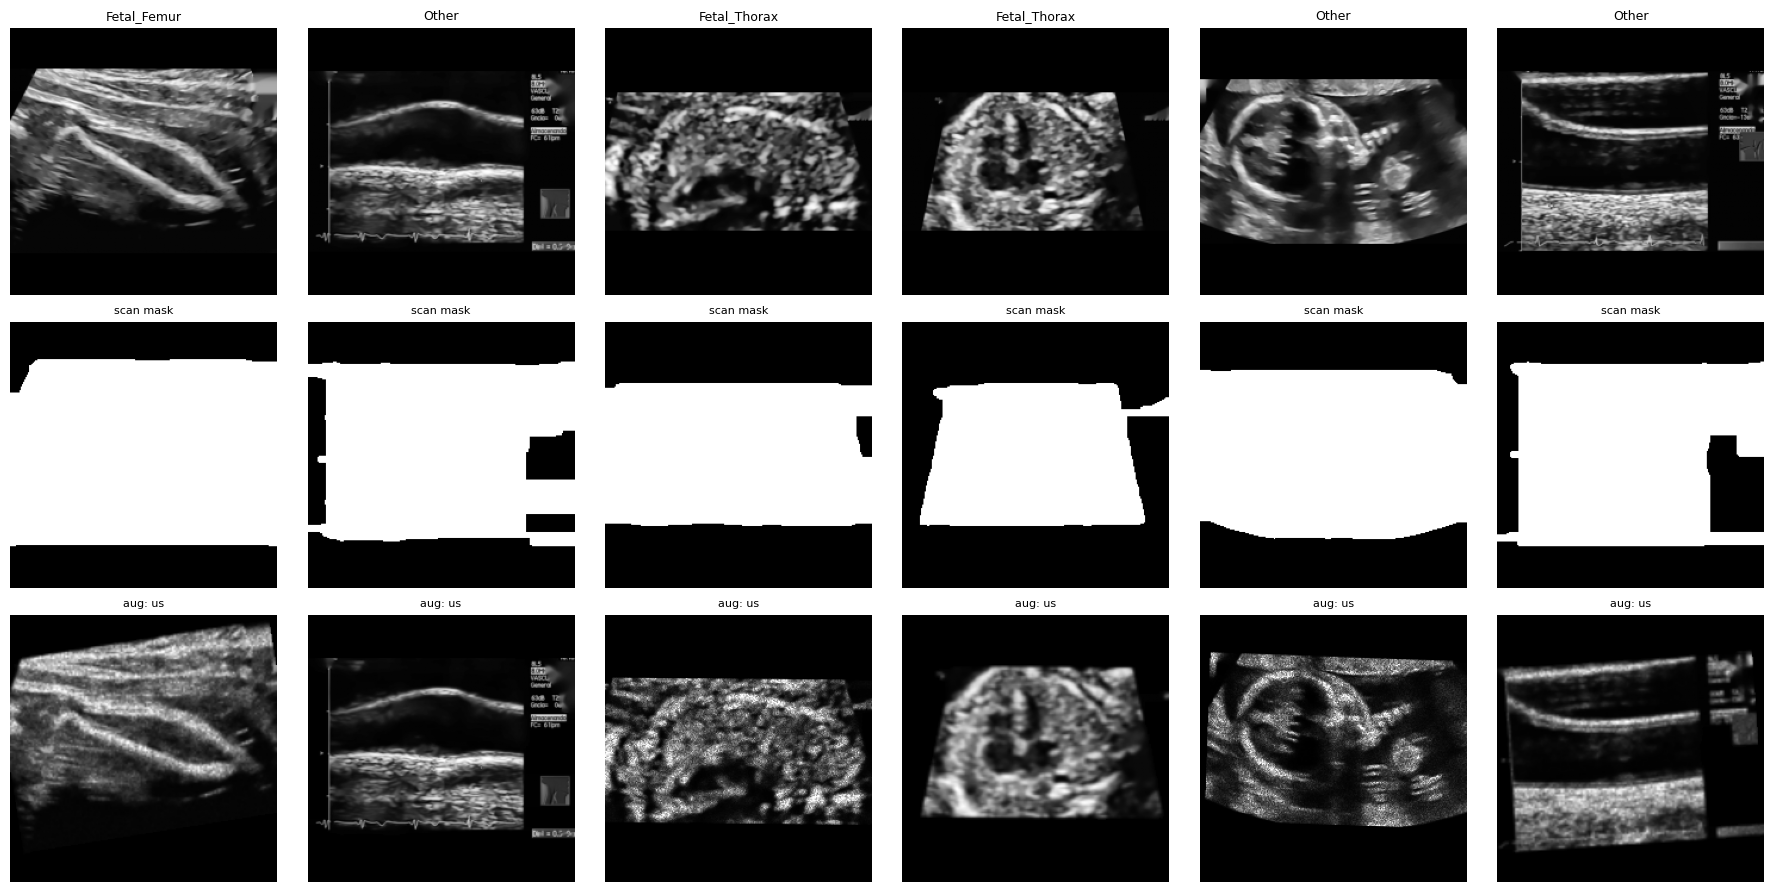

/tmp/ipykernel_23/987986596.py:22: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  probs = torch.softmax(torch.tensor(float(clip_model.logit_scale.exp()) * zi @ tf.T), -1).numpy()


ZERO-SHOT: {'acc': 94.37, 'macro_f1': 94.0839, 'bal_acc': np.float64(92.6236), 'ece': 0.0165, 'nll': 0.1594}
                 precision    recall  f1-score   support

  Fetal_Abdomen     0.9785    0.8911    0.9327       358
    Fetal_Brain     0.9100    0.9959    0.9510      1472
    Fetal_Femur     1.0000    0.9427    0.9705       524
   Fetal_Thorax     0.9962    0.8045    0.8902       660
Maternal_Cervix     0.9252    0.9969    0.9597       645

       accuracy                         0.9437      3659
      macro avg     0.9620    0.9262    0.9408      3659
   weighted avg     0.9478    0.9437    0.9426      3659

  probe C=0.001  val macro-F1=90.56
  probe C=0.01   val macro-F1=92.20
  probe C=0.1    val macro-F1=92.76
  probe C=1.0    val macro-F1=93.58
  probe C=10.0   val macro-F1=93.17
LINEAR PROBE (C=1.0): {'acc': 92.4493, 'macro_f1': 91.9134, 'bal_acc': np.float64(93.347), 'ece': 0.0488, 'nll': 0.3057}
                 precision    recall  f1-score   support

  Fetal_Abdomen 

,n,acc
machine,,
Aloka,1737,94.30
Other,57,87.72
Voluson E6,2406,92.77
Voluson S10,1071,88.98


trainable params: 304.0 M
ep 01 | loss 0.4696 | val acc 93.01 F1 92.98 ECE 0.0519 | 365s
ep 02 | loss 0.1239 | val acc 88.52 F1 87.28 ECE 0.0968 | 360s
ep 03 | loss 0.1089 | val acc 94.10 F1 93.68 ECE 0.0468 | 359s
ep 04 | loss 0.0832 | val acc 91.48 F1 90.11 ECE 0.0771 | 357s
ep 05 | loss 0.0669 | val acc 93.55 F1 92.55 ECE 0.0553 | 354s
ep 06 | loss 0.0678 | val acc 93.55 F1 93.01 ECE 0.0567 | 352s
ep 07 | loss 0.0455 | val acc 94.43 F1 93.40 ECE 0.0506 | 350s
ep 08 | loss 0.0496 | val acc 94.54 F1 93.80 ECE 0.0521 | 350s
ep 09 | loss 0.0563 | val acc 94.54 F1 93.80 ECE 0.0515 | 350s
ep 10 | loss 0.0494 | val acc 94.43 F1 93.90 ECE 0.0530 | 350s
ep 11 | loss 0.0256 | val acc 95.41 F1 94.72 ECE 0.0447 | 350s
ep 12 | loss 0.0255 | val acc 94.64 F1 93.95 ECE 0.0487 | 346s
ep 13 | loss 0.0306 | val acc 93.99 F1 93.53 ECE 0.0572 | 348s
ep 14 | loss 0.0261 | val acc 94.64 F1 94.22 ECE 0.0526 | 348s
ep 15 | loss 0.0310 | val acc 94.54 F1 94.13 ECE 0.0528 | 348s
ep 16 | loss 0.0156 | val acc

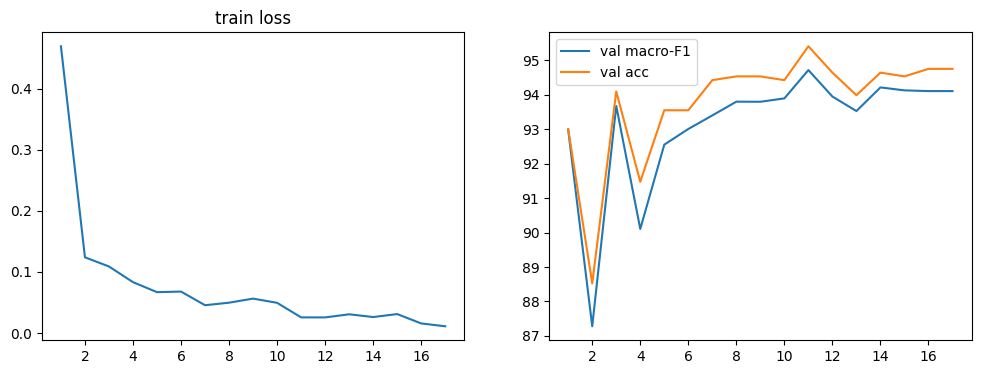

temperature (fit on val): 2.392


,acc,macro_f1,bal_acc,ece,nll,aurc,acc_cov90,acc_cov80
config,,,,,,,,
single,95.3140,94.7627,94.8655,0.0424,0.3492,0.01754,97.32,97.68
single+TS,95.3140,94.7627,94.8655,0.0100,0.1979,0.01762,97.24,97.46
TTA,95.4658,94.9261,95.0877,0.0358,0.2804,0.01412,97.74,98.15
TTA+TS,95.5037,94.9690,95.1008,0.0154,0.1820,0.01453,97.64,97.94
MC,95.3330,94.7925,94.8758,0.0423,0.3419,0.01763,97.30,97.72
TTA+MC,95.4468,94.9036,95.0559,0.0348,0.2755,0.01411,97.72,98.15
TTA+MC+TS,95.5227,94.9865,95.1111,0.0161,0.1825,0.01453,97.64,97.96


[TTA] patient-level bootstrap 95% CI: {'acc': (94.7834, 96.0762), 'macro_f1': (94.1887, 95.5958), 'bal_acc': (94.2753, 95.8477), 'ece': (0.0304, 0.0423)}
                 precision    recall  f1-score   support

  Fetal_Abdomen     0.9093    0.9525    0.9304       358
    Fetal_Brain     0.9959    0.9925    0.9942      1472
    Fetal_Femur     0.9159    0.8931    0.9043       524
   Fetal_Thorax     0.9466    0.9409    0.9438       660
Maternal_Cervix     0.9908    0.9969    0.9938       645
          Other     0.9287    0.9293    0.9290      1612

       accuracy                         0.9547      5271
      macro avg     0.9479    0.9509    0.9493      5271
   weighted avg     0.9547    0.9547    0.9546      5271



,n,acc
machine,,
Aloka,1737,97.47
Other,57,87.72
Voluson E6,2406,94.39
Voluson S10,1071,95.05


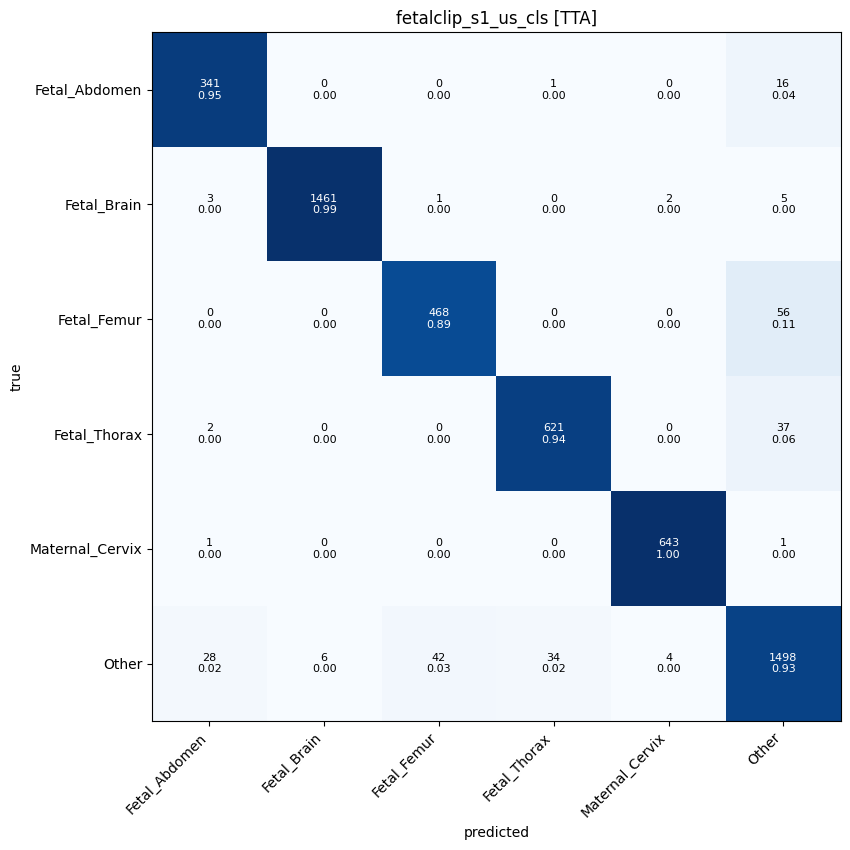

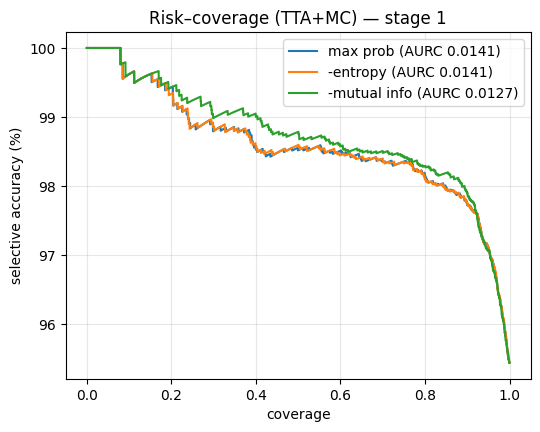

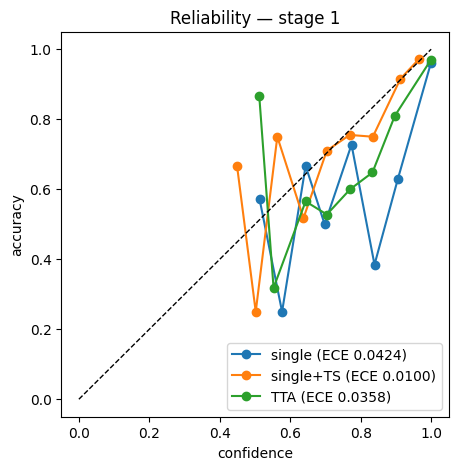

no baseline CSV found -> McNemar skipped
stage 1 done in 114.3 min
STAGE 2  |  fetalclip_s2_us_cls  |  /kaggle/input/datasets/paravibhatia/fetal-planes-final/brain_subplanes
classes: ['Trans_cerebellum', 'Trans_thalamic', 'Trans_ventricular']
  train   1340 [326, 759, 255]
  val      203 [49, 114, 40]
  test    1406 [339, 765, 302]
patient overlap: {'train_val': 0, 'train_test': 0, 'val_test': 0} (must be all 0)


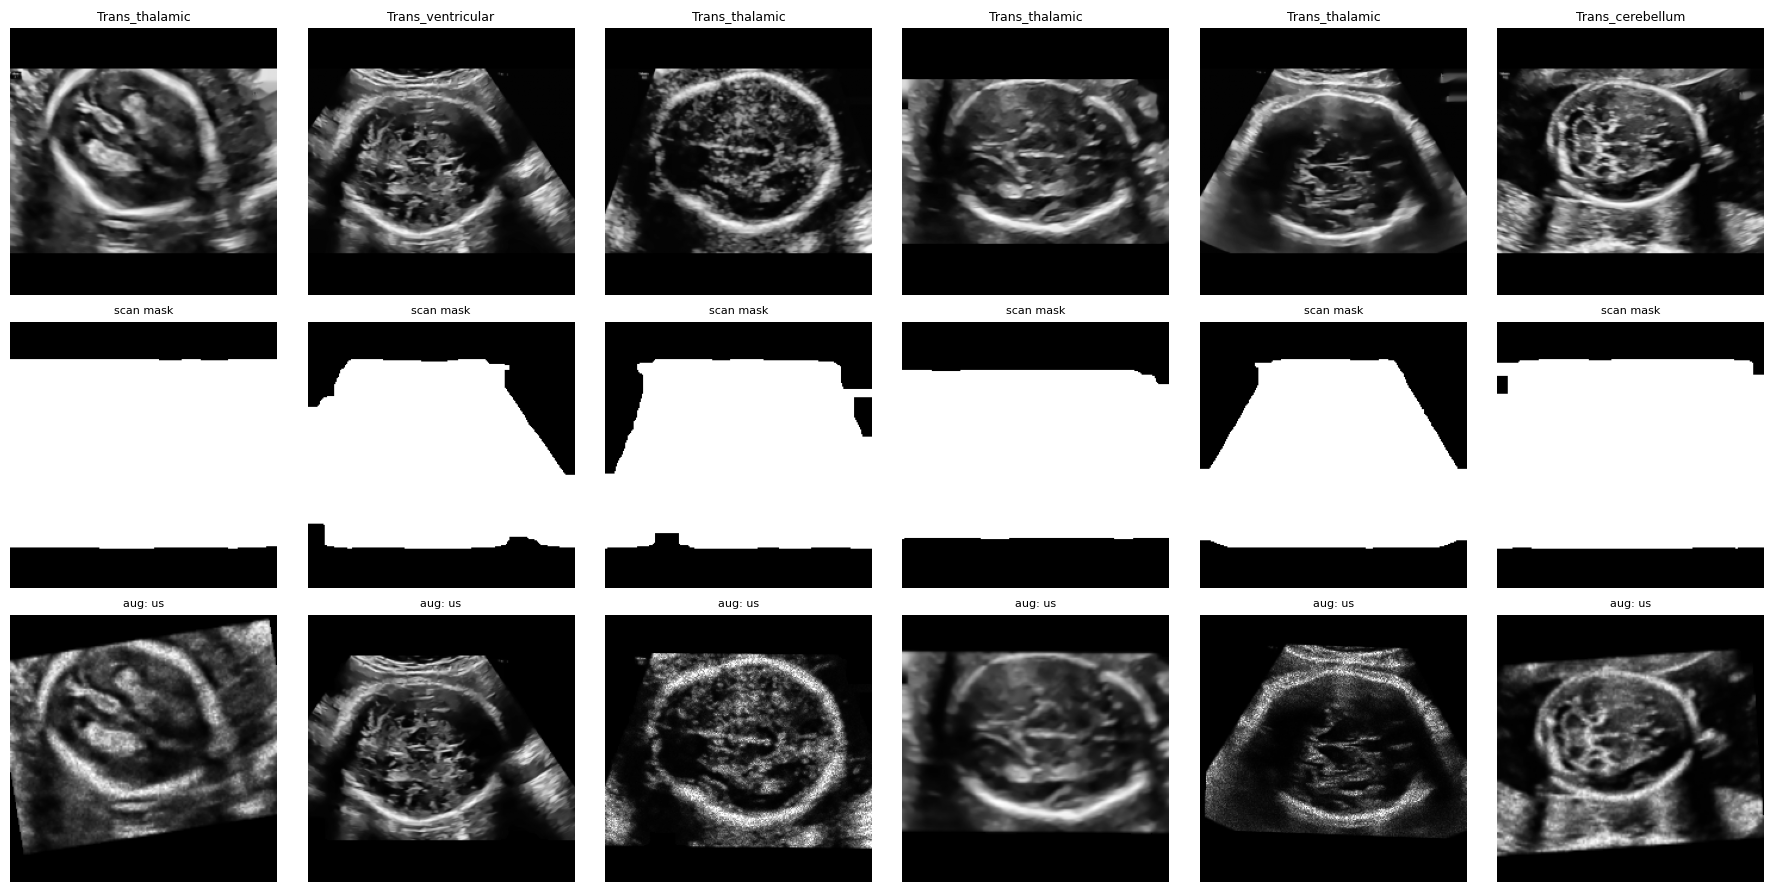

ZERO-SHOT: {'acc': 69.6302, 'macro_f1': 69.0078, 'bal_acc': np.float64(73.8928), 'ece': 0.1378, 'nll': 0.8571}
                   precision    recall  f1-score   support

 Trans_cerebellum     0.6429    0.9558    0.7687       339
   Trans_thalamic     0.8436    0.5922    0.6959       765
Trans_ventricular     0.5534    0.6689    0.6057       302

         accuracy                         0.6963      1406
        macro avg     0.6800    0.7389    0.6901      1406
     weighted avg     0.7329    0.6963    0.6940      1406

  probe C=0.001  val macro-F1=82.00
  probe C=0.01   val macro-F1=87.47
  probe C=0.1    val macro-F1=82.11
  probe C=1.0    val macro-F1=79.81
  probe C=10.0   val macro-F1=78.90
LINEAR PROBE (C=0.01): {'acc': 79.4452, 'macro_f1': 79.2138, 'bal_acc': np.float64(81.5124), 'ece': 0.0404, 'nll': 0.4905}
                   precision    recall  f1-score   support

 Trans_cerebellum     0.8457    0.8732    0.8592       339
   Trans_thalamic     0.8640    0.7477    0.8017   

,n,acc
machine,,
Aloka,237,80.17
Other,22,63.64
Voluson E6,902,81.82
Voluson S10,245,71.43


trainable params: 304.0 M
ep 01 | loss 0.7519 | val acc 85.22 F1 84.46 ECE 0.0539 | 79s
ep 02 | loss 0.4580 | val acc 89.16 F1 87.35 ECE 0.0666 | 78s
ep 03 | loss 0.3671 | val acc 89.66 F1 88.47 ECE 0.0466 | 78s
ep 04 | loss 0.3544 | val acc 88.18 F1 87.19 ECE 0.0380 | 78s
ep 05 | loss 0.3103 | val acc 87.68 F1 86.78 ECE 0.0580 | 78s
ep 06 | loss 0.2561 | val acc 86.70 F1 85.55 ECE 0.0405 | 78s
ep 07 | loss 0.2231 | val acc 84.73 F1 84.29 ECE 0.0813 | 78s
ep 08 | loss 0.2615 | val acc 88.18 F1 87.16 ECE 0.0435 | 78s
ep 09 | loss 0.1401 | val acc 85.22 F1 84.45 ECE 0.0863 | 78s
early stop


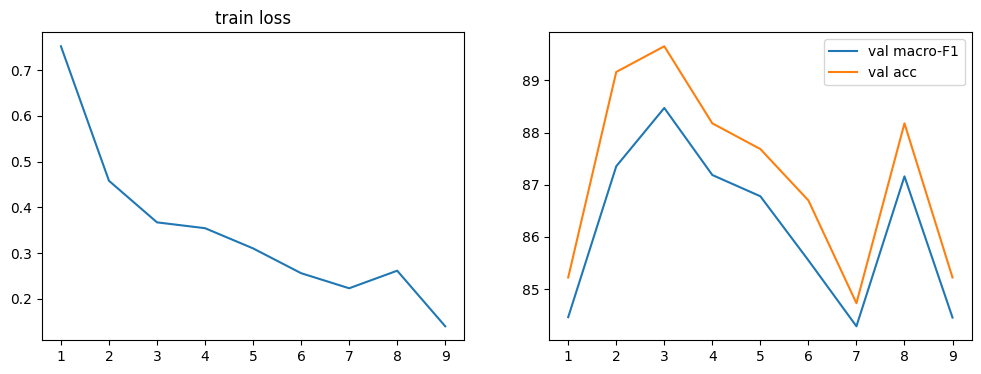

temperature (fit on val): 0.910


,acc,macro_f1,bal_acc,ece,nll,aurc,acc_cov90,acc_cov80
config,,,,,,,,
single,83.6415,83.0327,84.1391,0.0406,0.3967,0.05776,87.36,90.49
single+TS,83.6415,83.0327,84.1391,0.0540,0.4053,0.05761,87.36,90.58
TTA,84.1394,83.5463,84.5350,0.0258,0.3819,0.05500,87.20,90.67
TTA+TS,84.0683,83.4812,84.4914,0.0382,0.3857,0.05486,87.20,90.58
MC,83.6415,83.0360,84.1938,0.0377,0.3968,0.05822,87.36,90.40
TTA+MC,84.1394,83.5463,84.5350,0.0242,0.3819,0.05514,87.36,90.58
TTA+MC+TS,84.1394,83.5463,84.5350,0.0354,0.3852,0.05503,87.36,90.58


[TTA] patient-level bootstrap 95% CI: {'acc': (82.105, 86.1073), 'macro_f1': (81.3791, 85.6043), 'bal_acc': (82.2686, 86.676), 'ece': (0.0189, 0.049)}
                   precision    recall  f1-score   support

 Trans_cerebellum     0.8895    0.9027    0.8960       339
   Trans_thalamic     0.8769    0.8288    0.8522       765
Trans_ventricular     0.7168    0.8046    0.7582       302

         accuracy                         0.8414      1406
        macro avg     0.8278    0.8453    0.8355      1406
     weighted avg     0.8456    0.8414    0.8426      1406



,n,acc
machine,,
Aloka,237,86.50
Other,22,81.82
Voluson E6,902,84.81
Voluson S10,245,79.59


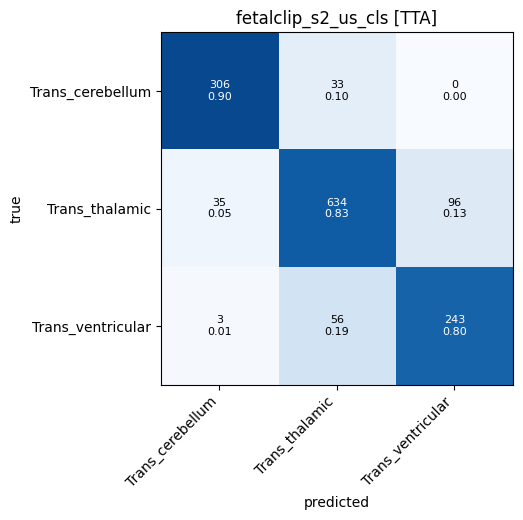

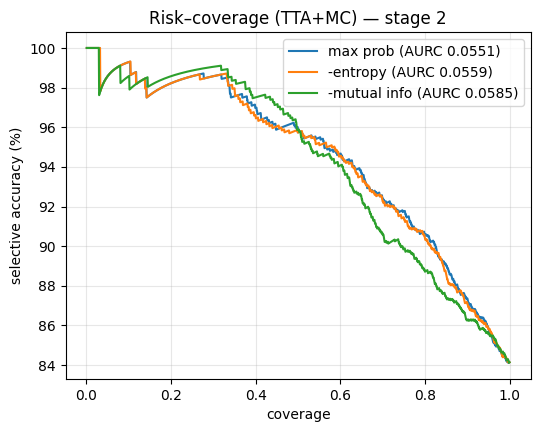

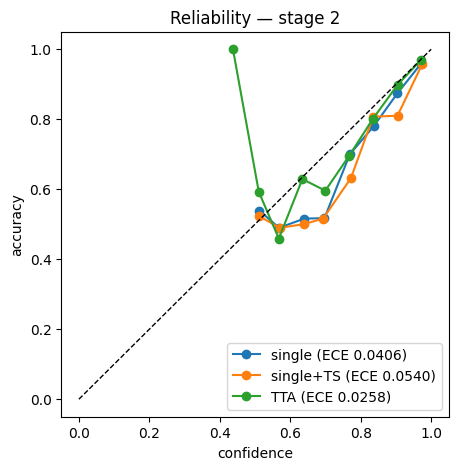

no baseline CSV found -> McNemar skipped
stage 2 done in 16.5 min


In [ ]:
T_START = time.time()
for st in RUN_STAGES:
    run_stage(st)

## 11. Cascade: Stage 1 → (if Brain) Stage 2, scored as one 8-class system
Ground truth = Stage-1 class for non-brain images, sub-plane for brain images that have a sub-plane label.
Brain images without a sub-plane label (not in `brain_subplanes/test`) are excluded and counted.
Confidence = p1(class) for non-brain predictions, p1(Brain)·p2(sub-plane) for brain predictions.

CASCADE on 5205 test images (66 brain images without sub-plane label excluded)
{'acc': 91.2584, 'macro_f1': 90.0302, 'bal_acc': np.float64(90.5033), 'ece': 0.0419, 'aurc': 0.0255, 'acc_cov90': 94.5571, 'acc_cov80': 95.9894} 
95% CI: {'acc': (90.3846, 92.0945), 'macro_f1': (89.1283, 90.9607), 'bal_acc': (89.4942, 91.5395), 'ece': (0.0351, 0.0497)}
                   precision    recall  f1-score   support

    Fetal_Abdomen     0.9167    0.9525    0.9342       358
      Fetal_Femur     0.9159    0.8931    0.9043       524
     Fetal_Thorax     0.9466    0.9409    0.9438       660
  Maternal_Cervix     0.9908    0.9969    0.9938       645
            Other     0.9310    0.9293    0.9301      1612
 Trans_cerebellum     0.8837    0.8968    0.8902       339
   Trans_thalamic     0.8729    0.8261    0.8489       765
Trans_ventricular     0.7147    0.8046    0.7570       302

         accuracy                         0.9126      5205
        macro avg     0.8965    0.9050    0.9003      5205


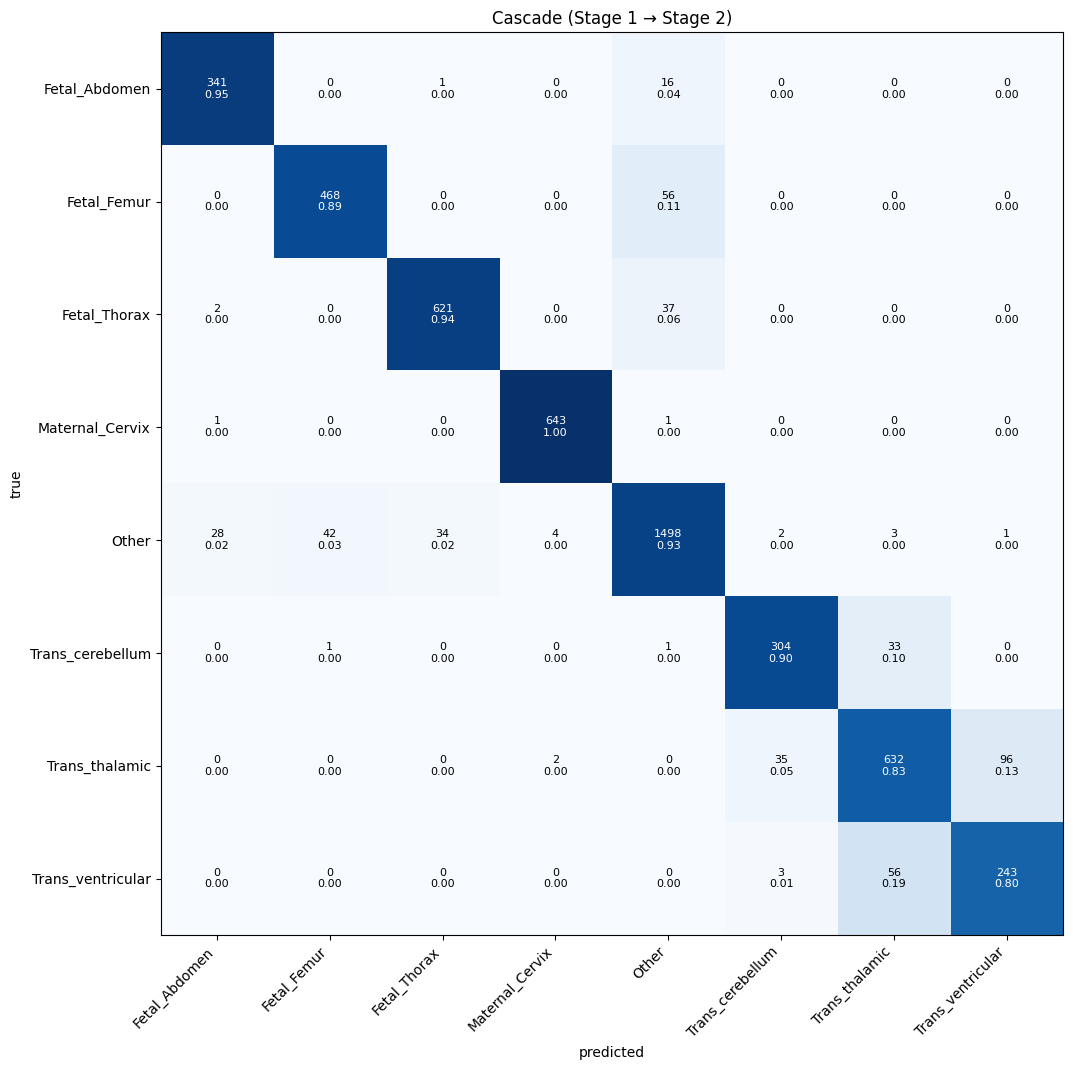

,n,acc
machine,,
Aloka,1717,95.69
Other,55,80.00
Voluson E6,2373,88.75
Voluson S10,1060,90.28


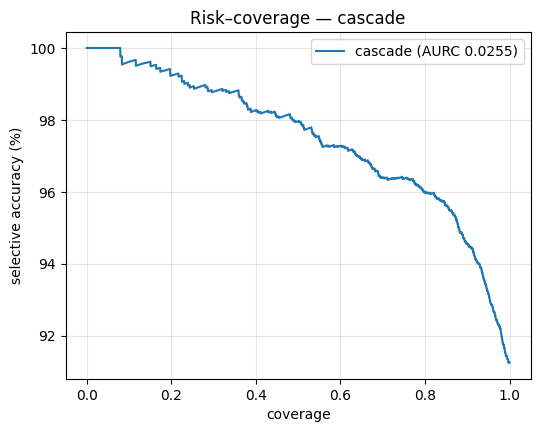

In [ ]:
if RUN_CASCADE and RUN_FINETUNE and 1 in STAGE_INFO and 2 in STAGE_INFO:
    s1, s2 = STAGE_INFO[1], STAGE_INFO[2]
    C1, C2 = s1["classes"], s2["classes"]
    bi = [i for i, c in enumerate(C1) if "brain" in c.lower()][0]
    p1_df = pd.read_csv(f"{s1['out']}/test_predictions.csv")
    P1 = p1_df[[f"p_{c}" for c in C1]].values
    assert list(p1_df.image.astype(str)) == list(s1["test"]["names"])

    m2 = build_classifier(len(C2), f"{s2['out']}/best.pt").eval()
    route = np.where(P1.argmax(1) == bi)[0]
    P2 = np.zeros((len(P1), len(C2)))
    if len(route):
        Z2 = extract(m2, subset(s1["test"], route), VIEWS)
        P2[route] = head_probs(m2, Z2)[0]
    del m2
    if DEVICE == "cuda": torch.cuda.empty_cache()

    CC = [c for i, c in enumerate(C1) if i != bi] + list(C2)            # 8 cascade classes
    sub_true = dict(zip(s2["test"]["names"], [C2[i] for i in s2["test"]["y"]]))
    y_true, keep = [], []
    for k, (n, y) in enumerate(zip(s1["test"]["names"], s1["test"]["y"])):
        if y != bi:
            y_true.append(C1[y]); keep.append(k)
        elif n in sub_true:
            y_true.append(sub_true[n]); keep.append(k)
    keep = np.array(keep)
    excluded = int(len(P1) - len(keep))
    pred_name, conf = [], []
    for k in keep:
        c1 = P1[k].argmax()
        if c1 != bi:
            pred_name.append(C1[c1]); conf.append(P1[k, c1])
        else:
            j = P2[k].argmax(); pred_name.append(C2[j]); conf.append(P1[k, bi] * P2[k, j])
    idx = {c: i for i, c in enumerate(CC)}
    yc, pc, conf = np.array([idx[c] for c in y_true]), np.array([idx[c] for c in pred_name]), np.array(conf)
    correct = (yc == pc).astype(float)
    pids_c = s1["test"]["pids"][keep]; names_c = [s1["test"]["names"][k] for k in keep]

    cm_ = dict(acc=100 * accuracy_score(yc, pc), macro_f1=100 * f1_score(yc, pc, average="macro"),
               bal_acc=100 * balanced_accuracy_score(yc, pc), ece=ece_from(conf, correct))
    cov, sa, aurc = risk_coverage(correct, conf)
    cm_.update(aurc=aurc, acc_cov90=acc_at_coverage(cov, sa, 0.9), acc_cov80=acc_at_coverage(cov, sa, 0.8))
    ci = cluster_bootstrap_ci(yc, pc, conf, pids_c)
    print(f"CASCADE on {len(keep)} test images ({excluded} brain images without sub-plane label excluded)")
    print({k: round(v, 4) for k, v in cm_.items()}, "\n95% CI:", ci)
    print(classification_report(yc, pc, labels=range(len(CC)), target_names=CC, digits=4, zero_division=0))
    COUT = f"{WORK}/fetalclip_cascade_{AUG}_{POOL}"; os.makedirs(COUT, exist_ok=True)
    plot_cm(yc, pc, CC, "Cascade (Stage 1 → Stage 2)", f"{COUT}/confusion_cascade.png")
    pmach = per_machine(names_c, correct)
    if pmach is not None: display(pmach); pmach.to_csv(f"{COUT}/per_machine.csv")
    plt.figure(figsize=(6, 4.5)); plt.plot(cov, 100 * sa, label=f"cascade (AURC {aurc:.4f})")
    plt.xlabel("coverage"); plt.ylabel("selective accuracy (%)"); plt.grid(alpha=.3); plt.legend()
    plt.title("Risk–coverage — cascade"); plt.savefig(f"{COUT}/risk_coverage.png", dpi=150); plt.show()
    pd.DataFrame(dict(image=names_c, patient=pids_c, true=y_true, pred=pred_name, conf=conf)).to_csv(
        f"{COUT}/cascade_predictions.csv", index=False)
    save_json(dict(classes=CC, n=len(keep), excluded_brain_without_subplane=excluded, **cm_, ci95=ci,
                   per_machine=None if pmach is None else pmach.to_dict(),
                   per_class=classification_report(yc, pc, labels=range(len(CC)), target_names=CC,
                                                   output_dict=True, zero_division=0)), f"{COUT}/results.json")
    SUMMARY.append(dict(stage="cascade", method="S1→S2 [TTA]", n_classes=len(CC), **{k: round(v, 4) for k, v in cm_.items()},
                        acc_ci95=ci["acc"], f1_ci95=ci["macro_f1"]))
else:
    print("cascade skipped (needs both stages fine-tuned)")

## 12. Summary + one zip with every result

In [ ]:
summary = pd.DataFrame(SUMMARY)
summary.to_csv(f"{WORK}/summary.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(summary)

tmp = "/tmp/fetalclip_results"
shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
for d in glob.glob(f"{WORK}/fetalclip_*"):
    if os.path.isdir(d):
        shutil.copytree(d, f"{tmp}/{os.path.basename(d)}", ignore=shutil.ignore_patterns("*.pt"))
shutil.copy(f"{WORK}/summary.csv", tmp)
shutil.make_archive(f"{WORK}/fetalclip_results", "zip", tmp)
print(f"total time: {(time.time()-T_START)/60:.1f} min")
print("download from the Output tab:  fetalclip_results.zip  (+ best.pt files inside each fetalclip_s*/ folder)")

,stage,method,n_classes,acc,macro_f1,bal_acc,ece,nll,acc_ci95,f1_ci95,aurc,acc_cov90,acc_cov80
0,1,zero-shot,5,94.3700,94.0839,92.6236,0.0165,0.1594,NaN,NaN,NaN,NaN,NaN
1,1,linear probe,6,92.4493,91.9134,93.3470,0.0488,0.3057,"(91.6354, 93.2977)","(91.0323, 92.7457)",NaN,NaN,NaN
2,1,fine-tune [single],6,95.3140,94.7627,94.8655,0.0424,0.3492,NaN,NaN,0.01754,97.3200,97.6800
3,1,fine-tune [TTA],6,95.4658,94.9261,95.0877,0.0358,0.2804,"(94.7834, 96.0762)","(94.1887, 95.5958)",0.01412,97.7400,98.1500
4,1,fine-tune [TTA+MC+TS],6,95.5227,94.9865,95.1111,0.0161,0.1825,NaN,NaN,0.01453,97.6400,97.9600
5,2,zero-shot,3,69.6302,69.0078,73.8928,0.1378,0.8571,NaN,NaN,NaN,NaN,NaN
6,2,linear probe,3,79.4452,79.2138,81.5124,0.0404,0.4905,"(77.1468, 81.667)","(76.8288, 81.4794)",NaN,NaN,NaN
7,2,fine-tune [single],3,83.6415,83.0327,84.1391,0.0406,0.3967,NaN,NaN,0.05776,87.3600,90.4900
8,2,fine-tune [TTA],3,84.1394,83.5463,84.5350,0.0258,0.3819,"(82.105, 86.1073)","(81.3791, 85.6043)",0.05500,87.2000,90.6700
9,2,fine-tune [TTA+MC+TS],3,84.1394,83.5463,84.5350,0.0354,0.3852,NaN,NaN,0.05503,87.3600,90.5800


total time: 133.2 min
download from the Output tab:  fetalclip_results.zip  (+ best.pt files inside each fetalclip_s*/ folder)
